# 05 — Compare all models

Reads every `results/*_metrics.json` written by notebooks 01-04b and builds the comparison tables and charts for your report.

**Safety checks at the top:** every model must have been trained on the CURRENT dataset (manifest md5 equals the md5 of `manifest.csv` on Drive), so a model trained on an older build can never slip into the comparison.

**Metrics that matter for the app**
* *accepted+correct* = a real leaf is accepted by the deployment rule AND gets the right class (the number a user actually experiences).
* *unknown rejected (avg of sources)* counts every unknown source equally (apple/tomato is ~40% of the images, so the pooled rate hides weak spots); *worst source* shows the weakest one.
* All differences between models on field/scene sets are tested with a **paired bootstrap** (same images for every model).

In [1]:
from google.colab import drive
drive.mount("/content/drive")
import json, glob, hashlib
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path("/content/drive/MyDrive/plant-disease-v2"); RES = ROOT / "results"
R = [json.load(open(f)) for f in sorted(glob.glob(str(RES / "*_metrics.json")))]
assert R, "no *_metrics.json found - run notebooks 01-04b first"
cur_md5 = hashlib.md5(open(ROOT / "manifest.csv", "rb").read()).hexdigest()
md5s = {r["model"]: r.get("manifest_md5") for r in R}
print("current dataset manifest md5:", cur_md5)
for m, v in md5s.items(): print(f"  {m:20s} {v}  {'OK' if v == cur_md5 else '<-- DIFFERENT DATASET'}")
stale = [m for m, v in md5s.items() if v != cur_md5]
assert not stale, f"these models were NOT trained on the current dataset -> retrain them: {stale}"
print("every model used the same, current split. sizes:", R[0]["split_sizes"])

nan = float("nan")
pct = lambda x, nd=1: round(x * 100, nd) if x is not None else nan
rows = []
for r in R:
    dp = r["deploy"]
    miss = [k for k in ("ood_rejected_macro", "ood_rejected_worst", "field_end_to_end") if k not in dp]
    assert not miss, f"{r['model']}: metrics were written by an older notebook ({miss} missing) - re-run it with the latest version"
    rows.append({
        "model": r["model"], "params (M)": round(r["params_m"], 1), "ckpt (MB)": round(r["ckpt_mb"]),
        "test acc %": pct(r["test"]["acc"], 2), "test F1 %": pct(r["test"]["macro_f1"], 2),
        "FIELD acc %": pct(r["field"]["acc"], 2), "FIELD F1 %": pct(r["field"]["macro_f1"], 2),
        "SCENE acc %": pct(r["scene"]["acc"], 2) if "scene" in r else nan,
        "ECE after T": round(r["ece_after"], 4),
        "OOD AUROC (maha)": round(r["ood"]["mahalanobis"]["auroc"], 4), "OOD AUROC (energy)": round(r["ood"]["energy"]["auroc"], 4),
        "unknown rejected % (avg of sources)": pct(dp["ood_rejected_macro"]), "worst source rejected %": pct(dp["ood_rejected_worst"]),
        "worst source": dp.get("ood_worst_source", ""), "unknown rejected % (pooled)": pct(dp["ood_rejected"]),
        "real leaves accepted % (field)": pct(dp["id_accept_field"]), "real leaves accepted % (scene)": pct(dp["id_accept_scene"]),
        "field accepted+correct %": pct(dp["field_end_to_end"]), "scene accepted+correct %": pct(dp.get("scene_end_to_end")),
        "robust mean acc %": pct(r["robustness_mean_acc_perturbed"], 2), "robust worst acc %": pct(r["robustness_worst_acc"], 2),
        "GPU ms": round(r["latency_gpu_fp32"]["mean_ms"], 1), "CPU ms": round(r["latency_cpu_fp32"]["mean_ms"], 1),
        "train min": round(r["train_minutes"], 1),
    })
TAB = pd.DataFrame(rows).set_index("model")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
display(TAB.T)
TAB.to_csv(RES / "final_comparison_v2.csv")

Mounted at /content/drive
current dataset manifest md5: c0c74aae5361191f93208dcd44c3a7f4
  convnext_tiny        c0c74aae5361191f93208dcd44c3a7f4  OK
  dinov2_vit_s14       c0c74aae5361191f93208dcd44c3a7f4  OK
  efficientnet_b0      c0c74aae5361191f93208dcd44c3a7f4  OK
  mobilenetv3_large    c0c74aae5361191f93208dcd44c3a7f4  OK
every model used the same, current split. sizes: {'train': 17253, 'val': 2041, 'test': 1410, 'field_test': 74, 'scene_test': 43, 'ood_test': 2324}


model,convnext_tiny,dinov2_vit_s14,efficientnet_b0,mobilenetv3_large
params (M),27.8,21.6,4.0,4.2
ckpt (MB),111,87,16,17
test acc %,99.57,99.43,99.36,99.29
test F1 %,99.21,99.08,98.89,98.92
FIELD acc %,77.03,83.78,78.38,81.08
FIELD F1 %,65.62,69.83,66.27,67.58
SCENE acc %,83.72,88.37,83.72,83.72
ECE after T,0.0193,0.0148,0.0186,0.0158
OOD AUROC (maha),0.9964,0.9947,0.9903,0.9673
OOD AUROC (energy),0.9895,0.9906,0.9923,0.9898


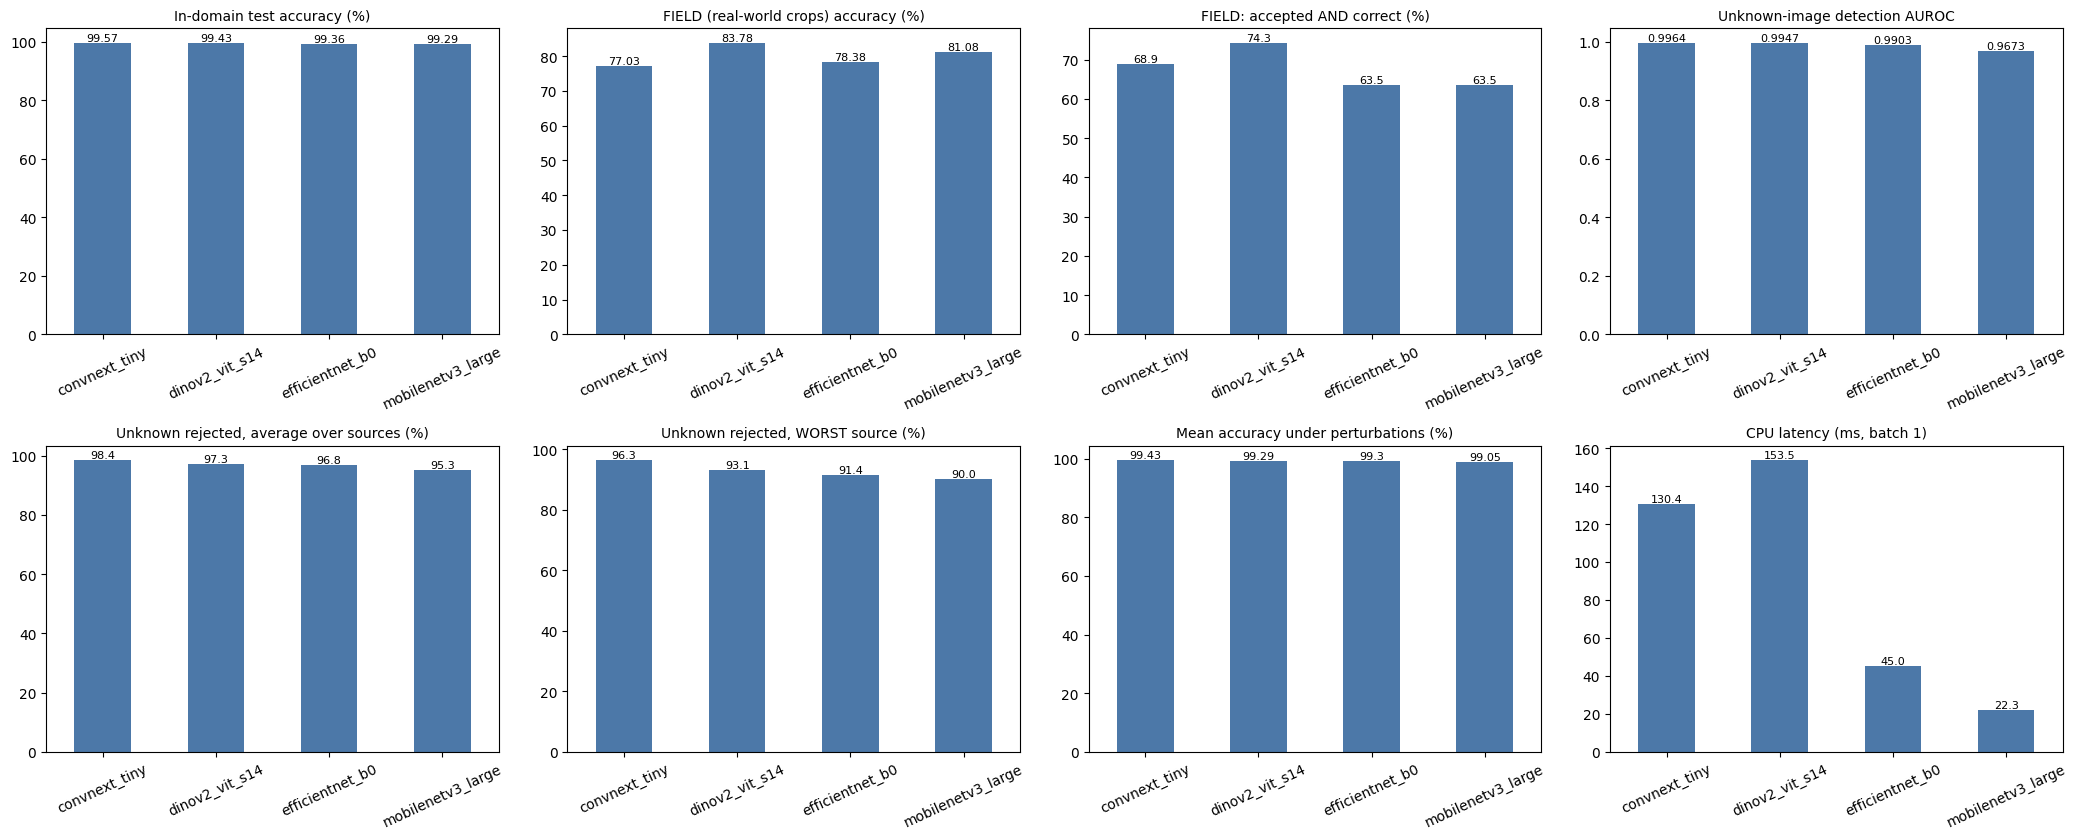

,convnext_tiny,dinov2_vit_s14,efficientnet_b0,mobilenetv3_large
clean,99.57,99.43,99.36,99.29
dark,99.79,99.29,99.50,99.43
bright,99.57,99.50,99.50,99.22
blur,99.22,99.36,99.57,99.01
jpeg,99.36,99.22,99.29,99.15
rotate,99.50,99.43,99.50,99.36
crop,99.22,99.01,99.15,99.22
noise,99.43,99.08,98.30,98.01
lowres,99.36,99.43,99.57,99.01


In [2]:
fig, ax = plt.subplots(2, 4, figsize=(21, 8.5)); ax = ax.ravel()
def bar(a, col, title):
    TAB[col].plot.bar(ax=a, color="#4c78a8"); a.set_title(title, fontsize=10); a.set_xlabel("")
    for i, v in enumerate(TAB[col]):
        if v == v: a.text(i, v, f"{v}", ha="center", va="bottom", fontsize=8)
    a.tick_params(axis="x", rotation=25)
bar(ax[0], "test acc %", "In-domain test accuracy (%)")
bar(ax[1], "FIELD acc %", "FIELD (real-world crops) accuracy (%)")
bar(ax[2], "field accepted+correct %", "FIELD: accepted AND correct (%)")
bar(ax[3], "OOD AUROC (maha)", "Unknown-image detection AUROC")
bar(ax[4], "unknown rejected % (avg of sources)", "Unknown rejected, average over sources (%)")
bar(ax[5], "worst source rejected %", "Unknown rejected, WORST source (%)")
bar(ax[6], "robust mean acc %", "Mean accuracy under perturbations (%)")
bar(ax[7], "CPU ms", "CPU latency (ms, batch 1)")
plt.tight_layout(); plt.savefig(RES / "final_comparison_v2.png", dpi=140); plt.show()

rob = pd.DataFrame({r["model"]: {c: r["robustness"][c]["acc"] * 100 for c in r["robustness"]} for r in R}).round(2)
display(rob)

In [3]:
# Which model for the backend?  Weighted score you can adjust.
TAB["field+scene acc %"] = TAB[["FIELD acc %", "SCENE acc %"]].mean(axis=1)                       # mean skips missing values
TAB["field+scene accepted+correct %"] = TAB[["field accepted+correct %", "scene accepted+correct %"]].mean(axis=1)
W = {"field+scene acc %": 0.20, "field+scene accepted+correct %": 0.20, "unknown rejected % (avg of sources)": 0.25,
     "worst source rejected %": 0.10, "robust mean acc %": 0.15, "test acc %": 0.10}          # sums to 1.0 - edit to match your priorities
assert abs(sum(W.values()) - 1) < 1e-9
cols = list(W); Z = (TAB[cols] - TAB[cols].min()) / (TAB[cols].max() - TAB[cols].min() + 1e-9)
score = sum(Z[k] * v for k, v in W.items()).sort_values(ascending=False)
print("Weighted ranking (0 = worst, 1 = best on every criterion):")
display(score.round(3).to_frame("score").join(TAB[["field+scene acc %", "field+scene accepted+correct %", "unknown rejected % (avg of sources)", "worst source rejected %",
                                                    "robust mean acc %", "test acc %", "CPU ms", "ckpt (MB)"]]))
print("Latency/size are NOT in the score: check them against your server budget.")

print("\nRED FLAGS (a high score does not hide these):")
flags = []
for m, row in TAB.iterrows():
    if row["real leaves accepted % (field)"] < 85: flags.append(f"{m}: only {row['real leaves accepted % (field)']}% of real field leaves are accepted -> too many rejections of genuine photos")
    if row["worst source rejected %"] < 60: flags.append(f"{m}: weakest unknown source ({row['worst source']}) is rejected only {row['worst source rejected %']}% of the time")
    if row["ECE after T"] > 0.10: flags.append(f"{m}: calibration is poor even after temperature scaling (ECE {row['ECE after T']})")
print("\n".join(flags) if flags else "none")

Weighted ranking (0 = worst, 1 = best on every criterion):


,score,field+scene acc %,field+scene accepted+correct %,unknown rejected % (avg of sources),worst source rejected %,robust mean acc %,test acc %,CPU ms,ckpt (MB)
model,,,,,,,,,
dinov2_vit_s14,0.755,86.075,76.70,97.3,93.1,99.29,99.43,153.5,87
convnext_tiny,0.699,80.375,72.80,98.4,96.3,99.43,99.57,130.4,111
efficientnet_b0,0.291,81.050,68.95,96.8,91.4,99.30,99.36,45.0,16
mobilenetv3_large,0.071,82.400,68.95,95.3,90.0,99.05,99.29,22.3,17


Latency/size are NOT in the score: check them against your server budget.

RED FLAGS (a high score does not hide these):
convnext_tiny: only 81.1% of real field leaves are accepted -> too many rejections of genuine photos
dinov2_vit_s14: only 83.8% of real field leaves are accepted -> too many rejections of genuine photos
efficientnet_b0: only 79.7% of real field leaves are accepted -> too many rejections of genuine photos
mobilenetv3_large: only 75.7% of real field leaves are accepted -> too many rejections of genuine photos


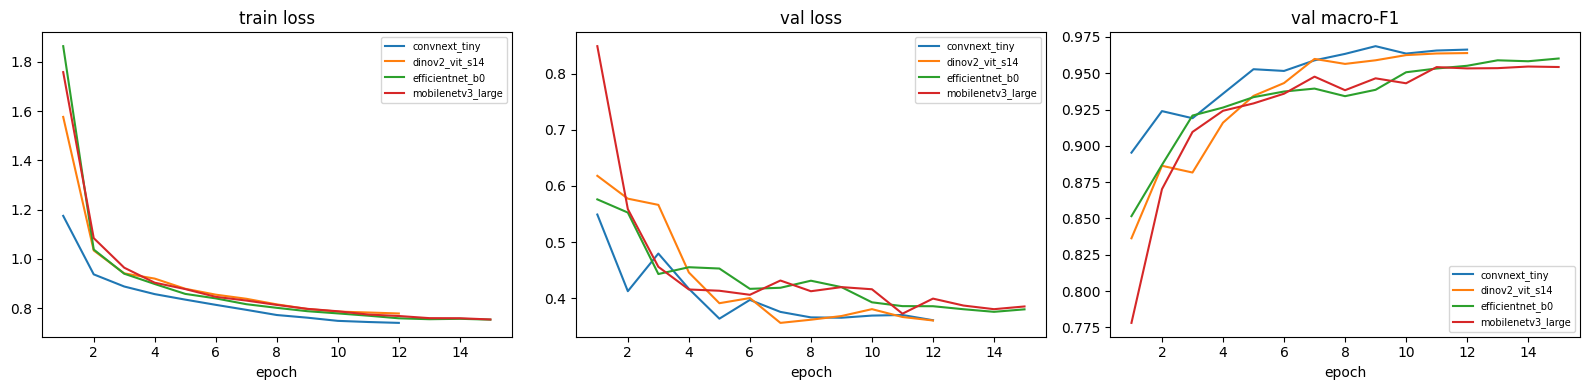

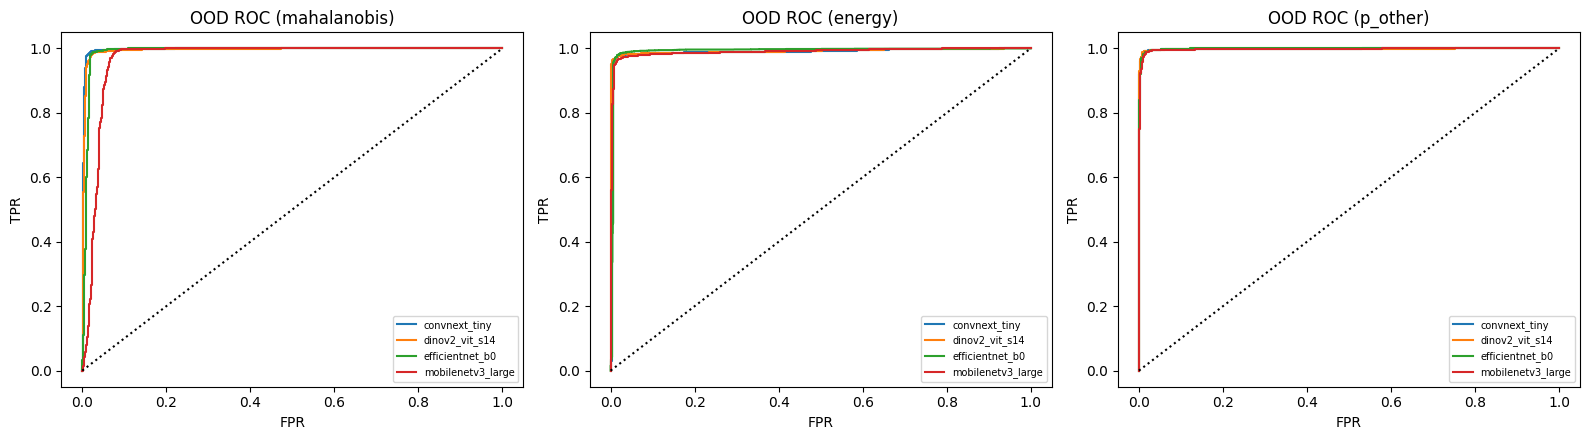

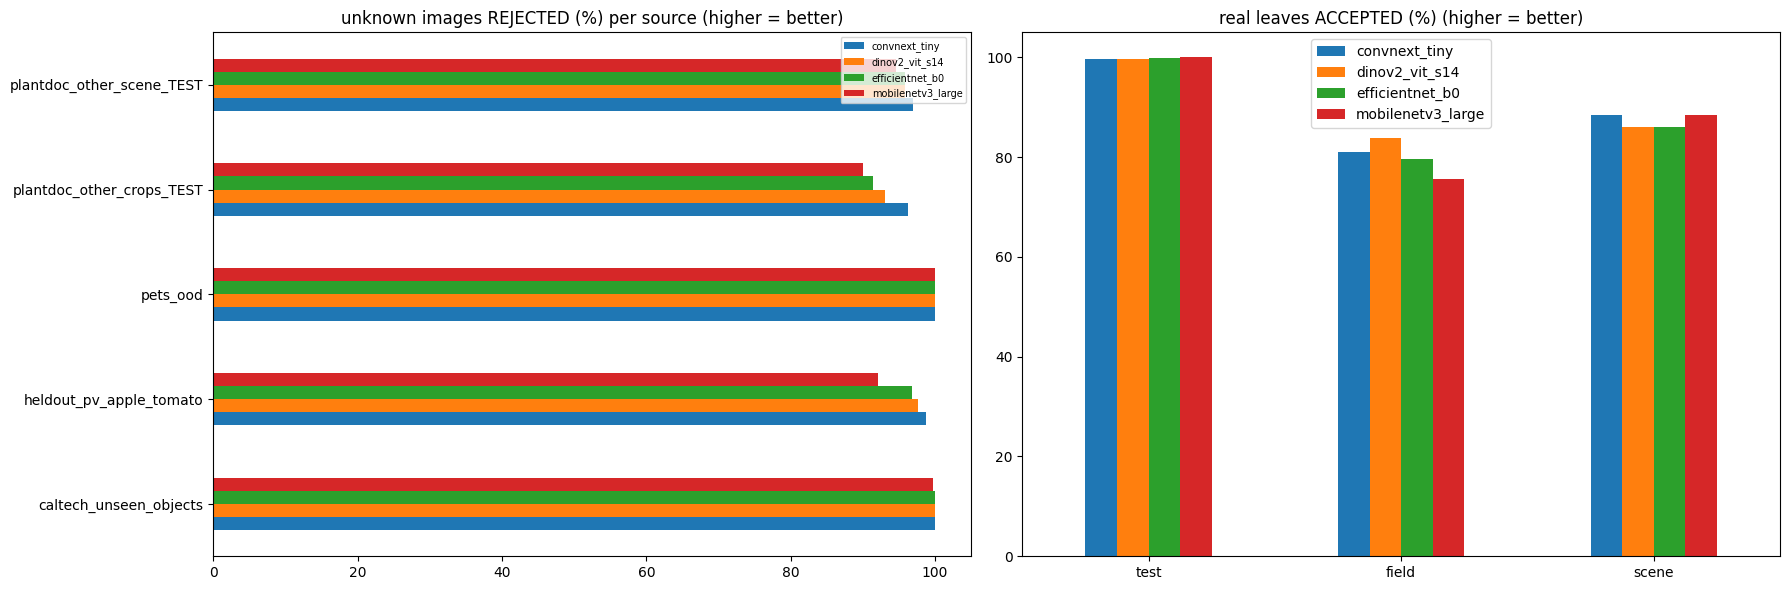

,convnext_tiny,dinov2_vit_s14,efficientnet_b0,mobilenetv3_large
caltech_unseen_objects,100.0,100.0,100.0,99.8
heldout_pv_apple_tomato,98.7,97.6,96.8,92.1
pets_ood,100.0,100.0,100.0,100.0
plantdoc_other_crops_TEST,96.3,93.1,91.4,90.0
plantdoc_other_scene_TEST,97.0,95.8,95.8,94.6


,convnext_tiny,dinov2_vit_s14,efficientnet_b0,mobilenetv3_large
test,99.7,99.7,99.8,100.0
field,81.1,83.8,79.7,75.7
scene,88.4,86.0,86.0,88.4


,model,set,n,acc,lo,hi
0,convnext_tiny,test,1410,99.57,99.22,99.86
1,convnext_tiny,field,74,77.03,67.57,86.49
2,convnext_tiny,scene,43,83.72,72.09,93.02
3,dinov2_vit_s14,test,1410,99.43,99.01,99.79
4,dinov2_vit_s14,field,74,83.78,74.32,91.89
5,dinov2_vit_s14,scene,43,88.37,79.07,97.67
6,efficientnet_b0,test,1410,99.36,98.87,99.72
7,efficientnet_b0,field,74,78.38,68.92,87.84
8,efficientnet_b0,scene,43,83.72,72.09,93.02
9,mobilenetv3_large,test,1410,99.29,98.79,99.72


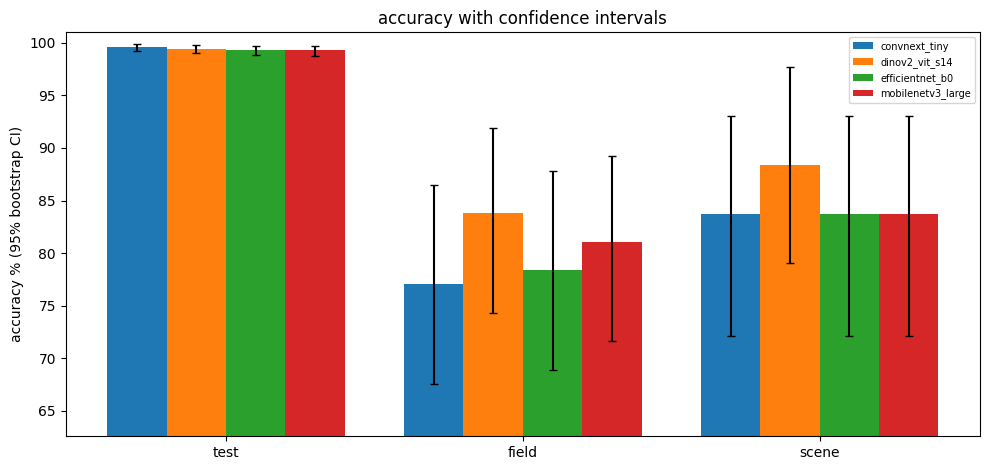

Paired bootstrap, field+scene accuracy: top-ranked model (dinov2_vit_s14) minus each other model


,best,other,n_images,diff_pts,ci_lo,ci_hi,verdict
0,dinov2_vit_s14,convnext_tiny,117,5.98,0.85,11.97,best is really better
1,dinov2_vit_s14,efficientnet_b0,117,5.13,0.00,11.11,NO significant difference
2,dinov2_vit_s14,mobilenetv3_large,117,3.42,-0.85,8.55,NO significant difference


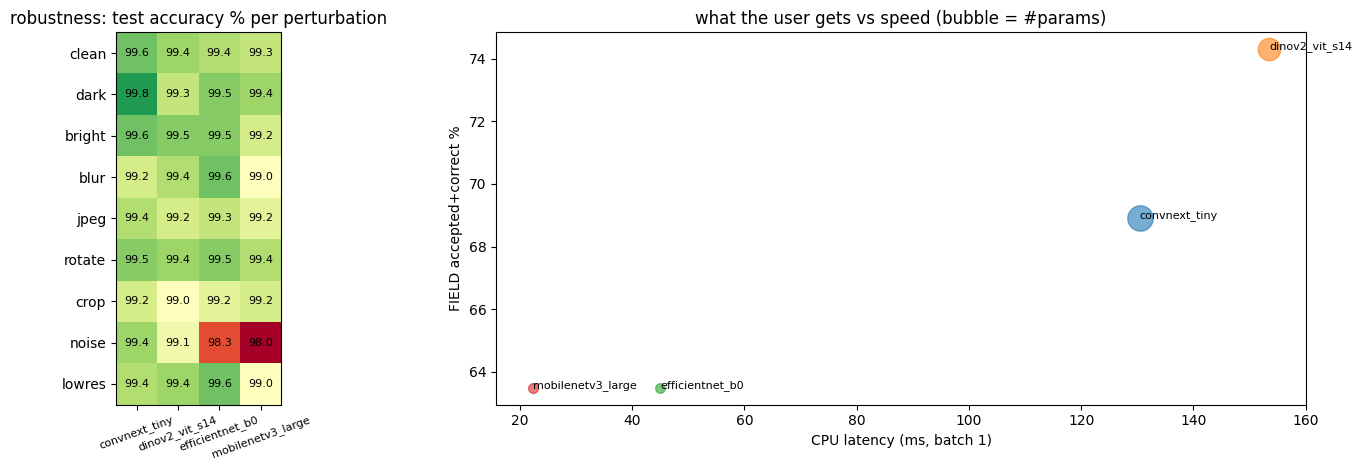

saved cmp_*.png / cmp_*.csv in /content/drive/MyDrive/plant-disease-v2/results


In [4]:
# ---------------- extra comparison plots (need *_outputs.npz + *_history.csv written by notebooks 01-04b) ----------------
from sklearn.metrics import roc_curve
O = {r["model"]: np.load(RES / f"{r['model']}_outputs.npz", allow_pickle=True) for r in R if (RES / f"{r['model']}_outputs.npz").exists()}
H = {r["model"]: pd.read_csv(RES / f"{r['model']}_history.csv") for r in R if (RES / f"{r['model']}_history.csv").exists()}
assert len(O) == len(R), f"missing *_outputs.npz for: {[r['model'] for r in R if r['model'] not in O]}"

# 1) training curves overlay
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m, h in H.items():
    ax[0].plot(h.epoch, h.train_loss, label=m); ax[1].plot(h.epoch, h.val_loss, label=m); ax[2].plot(h.epoch, h.val_f1, label=m)
for a, t in zip(ax, ["train loss", "val loss", "val macro-F1"]): a.set_title(t); a.set_xlabel("epoch"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(RES / "cmp_training_curves.png", dpi=140); plt.show()

# 2) OOD ROC overlay + acceptance / rejection per source
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, k in zip(ax, ["mahalanobis", "energy", "p_other"]):
    for m, o in O.items():
        yy = np.r_[np.zeros(len(o[f"id_{k}"])), np.ones(len(o[f"ood_{k}"]))]; f, t, _ = roc_curve(yy, np.r_[o[f"id_{k}"], o[f"ood_{k}"]]); a.plot(f, t, label=m)
    a.plot([0, 1], [0, 1], "k:"); a.set_title(f"OOD ROC ({k})"); a.set_xlabel("FPR"); a.set_ylabel("TPR"); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(RES / "cmp_ood_roc.png", dpi=140); plt.show()

srcs = sorted({s for r in R for s in r["deploy"]["ood_rejected_by_source"]})
rej = pd.DataFrame({r["model"]: {s: r["deploy"]["ood_rejected_by_source"].get(s, {}).get("rejected", np.nan) * 100 for s in srcs} for r in R})
accp = pd.DataFrame({r["model"]: {"test": pct(r["deploy"]["id_accept_test"]), "field": pct(r["deploy"]["id_accept_field"]),
                                  "scene": pct(r["deploy"]["id_accept_scene"])} for r in R})
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
rej.plot.barh(ax=ax[0]); ax[0].set_title("unknown images REJECTED (%) per source (higher = better)"); ax[0].set_xlim(0, 105); ax[0].legend(fontsize=7)
accp.plot.bar(ax=ax[1]); ax[1].set_title("real leaves ACCEPTED (%) (higher = better)"); ax[1].set_ylim(0, 105); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(RES / "cmp_deploy_rule.png", dpi=140); plt.show(); display(rej.round(1)); display(accp.round(1))

# 3) bootstrap 95% CI of accuracy (field / scene sets are small -> small differences are NOT significant)
def boot_ci(ok, n=2000, seed=0):
    r = np.random.RandomState(seed); b = [ok[r.randint(0, len(ok), len(ok))].mean() for _ in range(n)]
    return ok.mean() * 100, np.percentile(b, 2.5) * 100, np.percentile(b, 97.5) * 100
ci = []
for m, o in O.items():
    for s, nm in [("te", "test"), ("fd", "field"), ("sc", "scene")]:
        if len(o[f"y_{s}"]):
            a_, lo, hi = boot_ci((o[f"lg_{s}"].argmax(1) == o[f"y_{s}"]).astype(float)); ci.append(dict(model=m, set=nm, n=len(o[f"y_{s}"]), acc=a_, lo=lo, hi=hi))
ci = pd.DataFrame(ci); ci.to_csv(RES / "cmp_bootstrap_ci.csv", index=False); display(ci.round(2))
fig, ax = plt.subplots(figsize=(10, 4.8)); w = .8 / max(1, len(O)); sets_ = list(ci.set.unique())
for i, (m, g) in enumerate(ci.groupby("model", sort=False)):
    g = g.set_index("set").reindex(sets_); x = np.arange(len(sets_)) + i * w
    ax.bar(x, g.acc, w, yerr=[(g.acc - g.lo).fillna(0), (g.hi - g.acc).fillna(0)], capsize=3, label=m)
ax.set_xticks(np.arange(len(sets_)) + .4 - w / 2); ax.set_xticklabels(sets_)
ax.set_ylim(max(0, ci.lo.min() - 5), 101); ax.set_ylabel("accuracy % (95% bootstrap CI)"); ax.legend(fontsize=7); ax.set_title("accuracy with confidence intervals")
plt.tight_layout(); plt.savefig(RES / "cmp_accuracy_ci.png", dpi=140); plt.show()

# 3b) PAIRED bootstrap on field+scene (same images for every model -> much tighter than comparing the intervals above)
def pooled_ok(o): return np.concatenate([(o["lg_fd"].argmax(1) == o["y_fd"]), (o["lg_sc"].argmax(1) == o["y_sc"])]).astype(float)
best = score.index[0]; ob = O[best]
for m, o in O.items():
    assert np.array_equal(o["y_fd"], ob["y_fd"]) and np.array_equal(o["y_sc"], ob["y_sc"]), "field/scene label order differs between models"
okb = pooled_ok(ob); rs_ = np.random.RandomState(1); idx = [rs_.randint(0, len(okb), len(okb)) for _ in range(5000)]
pr = []
for m, o in O.items():
    if m == best: continue
    d_ = okb - pooled_ok(o); b = np.array([d_[i].mean() for i in idx]) * 100
    lo, hi = np.percentile(b, [2.5, 97.5]); pr.append(dict(best=best, other=m, n_images=len(okb), diff_pts=d_.mean() * 100, ci_lo=lo, ci_hi=hi,
                                                        verdict="best is really better" if lo > 0 else ("other is really better" if hi < 0 else "NO significant difference")))
print(f"Paired bootstrap, field+scene accuracy: top-ranked model ({best}) minus each other model")
display(pd.DataFrame(pr).round(2)); pd.DataFrame(pr).to_csv(RES / "cmp_paired_bootstrap.csv", index=False)

# 4) robustness heat-map + accuracy / latency / size trade-off
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].imshow(rob.values, cmap="RdYlGn", vmin=rob.values.min(), vmax=100); ax[0].set_xticks(range(rob.shape[1])); ax[0].set_xticklabels(rob.columns, rotation=20, fontsize=8)
ax[0].set_yticks(range(rob.shape[0])); ax[0].set_yticklabels(rob.index)
for i in range(rob.shape[0]):
    for j in range(rob.shape[1]): ax[0].text(j, i, f"{rob.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax[0].set_title("robustness: test accuracy % per perturbation")
for m in TAB.index:
    ax[1].scatter(TAB.loc[m, "CPU ms"], TAB.loc[m, "field accepted+correct %"], s=TAB.loc[m, "params (M)"] * 12, alpha=.6); ax[1].annotate(m, (TAB.loc[m, "CPU ms"], TAB.loc[m, "field accepted+correct %"]), fontsize=8)
ax[1].set_xlabel("CPU latency (ms, batch 1)"); ax[1].set_ylabel("FIELD accepted+correct %"); ax[1].set_title("what the user gets vs speed (bubble = #params)")
plt.tight_layout(); plt.savefig(RES / "cmp_robustness_tradeoff.png", dpi=140); plt.show()
print("saved cmp_*.png / cmp_*.csv in", RES)